# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

current_dir = os.path.dirname(os.path.abspath("Incremental-Learning-MycroftMinds"))
parent_dir = os.path.dirname(current_dir)
# Insert the parent directory at the beginning of sys.path if it's not already there.
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

## Import external libs and internal models

In [2]:
import time
from typing import Optional, Tuple, Dict, Any, List

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
#from river.ensemble import BaggingRegressor, SRPRegressor
from river.tree import HoeffdingTreeRegressor, HoeffdingAdaptiveTreeRegressor
#from river.drift.binary import DDM, EDDM
from src.bagging import ARFRegressorFODT
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.trees import fastodt
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_splits_seq_fit_predict

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../data/first_batch'

## Pick the hourly or 5-min granularity data
- WFV, train+=28 (train set increasing), validation=28, hourly granularity
- WFV, train+=28 (train set increasing), validation=28, 5-min granularity

In [4]:
HOURLY = True

In [5]:
# Measure loading time
start_time = time.time()

# Load data
if HOURLY:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='dev_4_hourly_wfv', use_numpy=True)
    features = ['time', 'device_id', 'hour', 'weekday', 'month', 
                 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 
                 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 
                 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 
                 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 
                 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_react_power_lag_1h', 'L2_react_power_lag_24h', 
                 'L2_voltage_lag_1h', 'L2_voltage_lag_24h', 
                 'L3_act_power_lag_1h', 'L3_act_power_lag_24h', 'L3_app_power_lag_1h', 'L3_app_power_lag_24h', 
                 'L3_current_lag_1h', 'L3_current_lag_24h', 'L3_react_power_lag_1h', 'L3_react_power_lag_24h', 
                 'L3_voltage_lag_1h', 'L3_voltage_lag_24h', 
                 'grid_freq_lag_1h', 'grid_freq_lag_24h', 
                 'powerfactor1_lag_1h', 'powerfactor1_lag_24h', 
                 'powerfactor2_lag_1h', 'powerfactor2_lag_24h', 
                 'powerfactor3_lag_1h', 'powerfactor3_lag_24h']
else:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='8_dev_5_min_wfv', use_numpy=True)
    # copy features from dataloader printouts
    features = []

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 7 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 7 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.01 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 7 splits
Validation data: 7 splits
First train split shape: X=(554, 43), y=(554,)
First valid split shape: X=(573, 43), y=(573,)

Memory usage:
Train: 5.34 MB
Valid: 1.24 MB
Test: 0.36 MB
Total: 6.95 MB


# Model evaluation

## Hourly granularity

### Baseline model (predict previous value)

In [7]:
device_period_metrics = {}
for split in valid:
    for device_id in set(split[0][:, 1]):  # Assuming device_id is in the second column
        X_valid, y_valid = get_device_data(split, device_id=device_id)
        y_pred = y_valid.shift(1)
        y_pred.iloc[0] = y_valid.iloc[0]
        
        device_metrics = calculate_metrics(
            y_valid,
            y_pred,
            device_id,
            f"{X_valid[0, 0]} - {X_valid[-1, 0]}", 
            verbose=True
            )
        
        if device_id not in device_period_metrics:
            device_period_metrics[device_id] = []
        device_period_metrics[device_id].append(device_metrics)

Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2600
	MAE: 0.1510
	MAPE: 17.9418%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2600
	MAE: 0.1510
	MAPE: 17.9418%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 0.3596
	MAE: 0.1442
	MAPE: 0.9412%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 0.7703
	MAE: 0.4431
	MAPE: 0.8657%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 1.7066
	MAE: 1.7066
	MAPE: 0.3484%
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2

In [8]:
all_time_metrics = all_time_aggregation_metrics(device_period_metrics, verbose=True)



Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.2448 ± 0.0277
	MAE: 0.1374 ± 0.0220
	MAPE: 0.2640 ± 0.0705
Hourly Metrics:
	RMSE: 0.2342 ± 0.0298
	MAE: 0.1275 ± 0.0298
	MAPE: 0.2420 ± 0.0718
Daily Metrics:
	RMSE: 0.3570 ± 0.1140
	MAE: 0.1413 ± 0.0397
	MAPE: 0.0173 ± 0.0079
Weekly Metrics:
	RMSE: 0.7995 ± 0.2727
	MAE: 0.5339 ± 0.2471
	MAPE: 0.0144 ± 0.0118
28_days Metrics:
	RMSE: 0.9885 ± 0.5248
	MAE: 0.9833 ± 0.5211
	MAPE: 0.0044 ± 0.0035


#### Validation plots

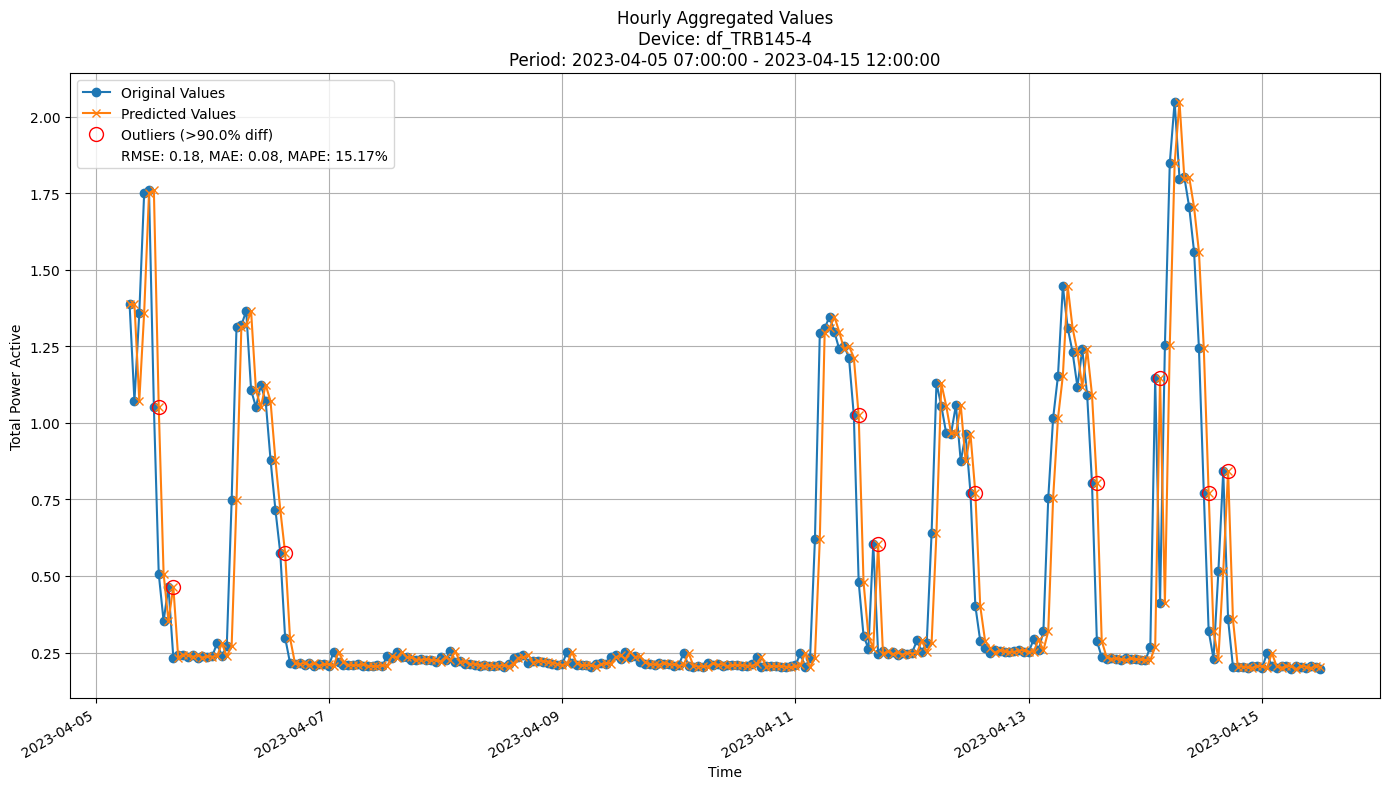

In [9]:
plot_hourly_predictions(y_valid, 
                        y_pred, 
                        device_id, 
                        outlier_threshold=0.9)

### GBDT

In [10]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.01,
    subsample=0.8,
    max_depth=6,
    random_state=42)

gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_splits_seq_fit_predict(
    model=gbdt, 
    train=train, 
    valid=valid, 
    incremental=False, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=False
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00

Time: 1.96 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2022-10-22 13:00:00 to 2022-11-05 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-05 13:00:00

Time: 2.82 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2022-11-05 14:00:00 to 2022-11-15 09:00:00

-------------------------


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00

Time: 3.52 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2022-11-15 10:00:00 to 2022-11-29 10:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-29 10:00:00

Time: 4.73 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2022-11-29 11:00:00 to 2022-12-09 07:00:00

-------------------------


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00

Time: 11.11 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2023-03-12 09:00:00 to 2023-03-26 09:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-03-26 09:00:00

Time: 12.23 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2023-03-26 10:00:00 to 2023-04-05 06:00:00

-------------------------


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00

Time: 13.69 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2023-04-05 07:00:00 to 2023-04-15 12:00:00

-------------------------


#### Results

In [11]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.1531 ± 0.0230
	MAE: 0.1075 ± 0.0141
	MAPE: 0.2270 ± 0.0361
Hourly Metrics:
	RMSE: 0.1380 ± 0.0223
	MAE: 0.0874 ± 0.0140
	MAPE: 0.1841 ± 0.0324
Daily Metrics:
	RMSE: 1.3858 ± 0.1691
	MAE: 1.0501 ± 0.1575
	MAPE: 0.0950 ± 0.0130
Weekly Metrics:
	RMSE: 4.1856 ± 0.7505
	MAE: 3.2586 ± 0.5963
	MAPE: 0.0531 ± 0.0150
28_days Metrics:
	RMSE: 11.9473 ± 3.5234
	MAE: 10.3338 ± 2.8792
	MAPE: 0.0405 ± 0.0051


Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.2504 ± 0.0463
	MAE: 0.1736 ± 0.0332
	MAPE: 0.4003 ± 0.0988
Hourly Metrics:
	RMSE: 0.2395 ± 0.0472
	MAE: 0.1596 ± 0.0366
	MAPE: 0.3608 ± 0.0669
Daily Metrics:
	RMSE: 2.3015 ± 0.7522
	MAE: 1.8986 ± 0.6558
	MAPE: 0.1893 ± 0.0359
Weekly Metrics:
	RMSE: 7.5313 ± 2.6756
	MAE: 6.4699 ± 2.5335


#### Feature importance
[WiP] Right now only for the last split and last device

In [12]:
feat_imps = sorted(
    zip(features[2:], gbdt.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


[('L1_current_lag_1h', 0.5484391365887257),
 ('hour', 0.08774805696025723),
 ('L2_act_power_lag_1h', 0.08521933233849191),
 ('L2_current_lag_1h', 0.07883212140737896),
 ('L1_app_power_lag_1h', 0.03445617134798537),
 ('L3_react_power_lag_1h', 0.029322257326210723),
 ('month', 0.01588708485520924),
 ('L2_app_power_lag_1h', 0.012241404491120413),
 ('powerfactor3_lag_1h', 0.00870102193946208),
 ('L1_act_power_lag_1h', 0.0067695776167741185),
 ('grid_freq_lag_1h', 0.006194200349359337),
 ('L3_act_power_lag_1h', 0.005845172349816348),
 ('L3_app_power_lag_1h', 0.005563150224138927),
 ('L3_react_power_lag_24h', 0.0054614272206022964),
 ('powerfactor2_lag_24h', 0.005274743190529659),
 ('L2_act_power_lag_24h', 0.00517120274115817),
 ('L3_current_lag_1h', 0.0038829205081952005),
 ('grid_freq_lag_24h', 0.0038216117745582803),
 ('weekday', 0.0034989313321583094),
 ('powerfactor1_lag_1h', 0.0034510837377848616),
 ('L2_app_power_lag_24h', 0.0033883989105568664),
 ('L1_app_power_lag_24h', 0.0033755392

#### Training plots
Plot only the last period of predictions

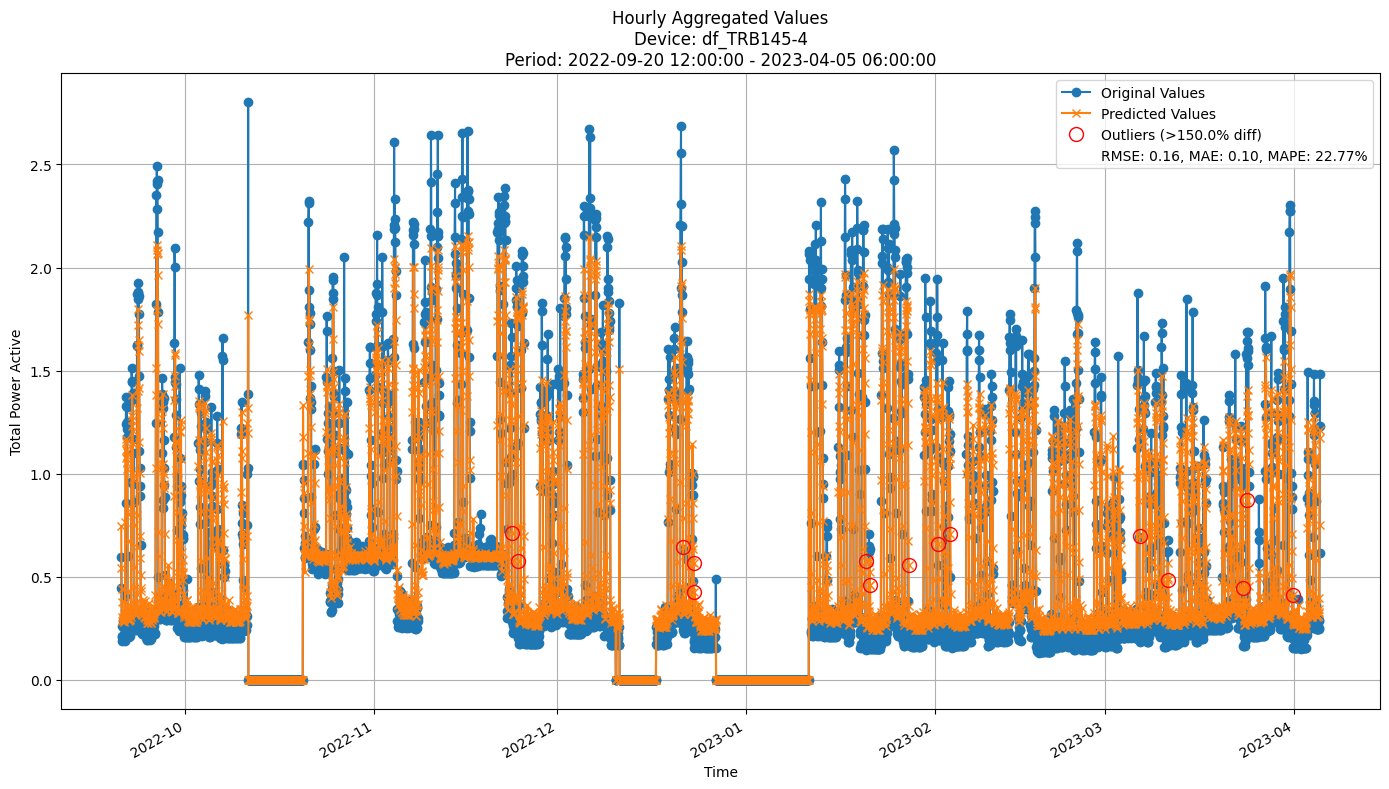

In [13]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=1.5)
# 48, 32, 61

#### Validation plots
Plot only the last period of predictions

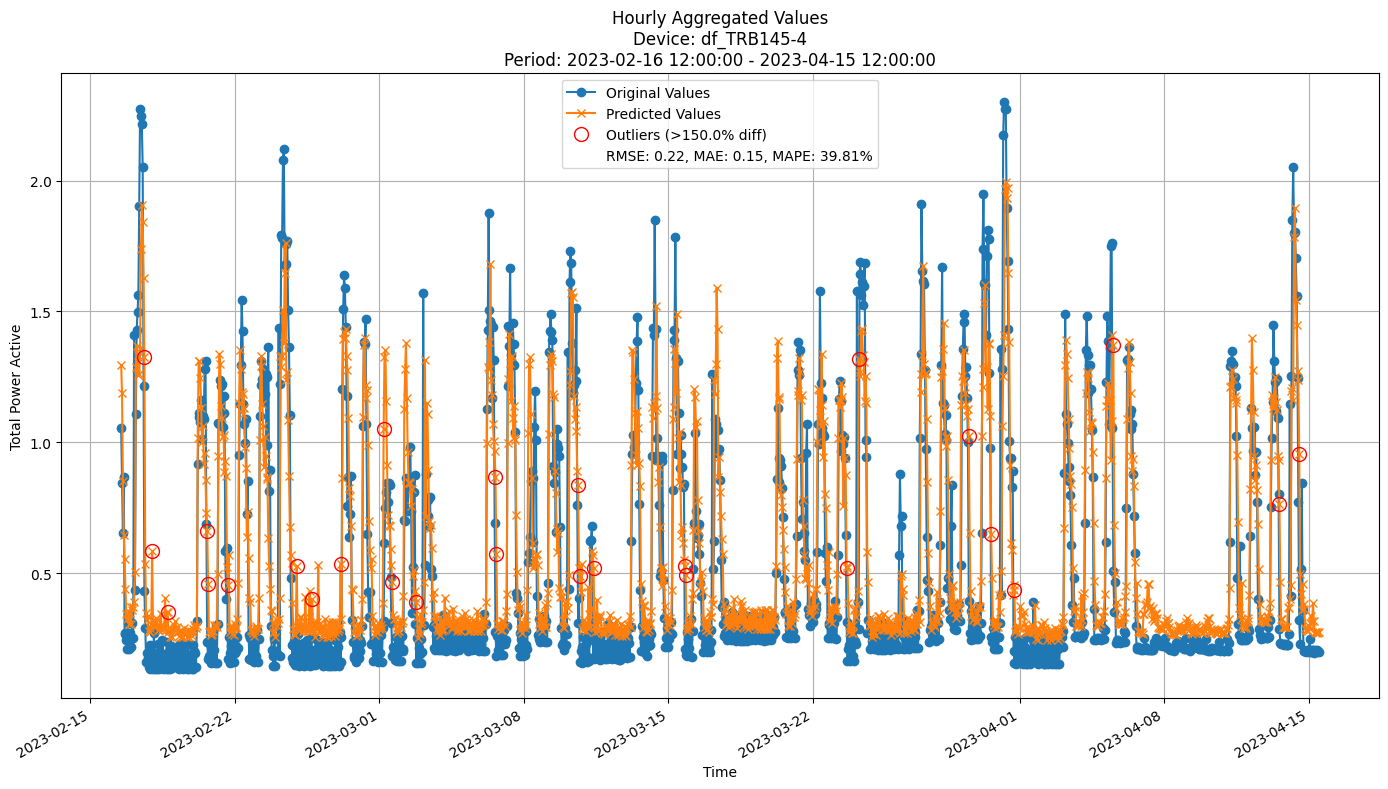

In [14]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Random Forest model

In [15]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor(
    n_estimators=100, 
    max_depth=4,
    max_features=0.8,
    random_state=42, 
    n_jobs=-1)

rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_splits_seq_fit_predict(
    model=rf, 
    train=train, 
    valid=valid, 
    incremental=False, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00

Time: 0.15 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2022-10-22 13:00:00 to 2022-11-05 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-05 13:00:00

Time: 0.17 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2022-11-05 14:00:00 to 2022-11-15 09:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2941
	MAE: 0.1899
	MAPE: 22.8102%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2941
	MAE: 0.1899
	MAPE: 22.8102%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.2466
	MAE: 2.7325
	MAPE

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00

Time: 0.21 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2022-11-15 10:00:00 to 2022-11-29 10:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-29 10:00:00

Time: 0.20 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2022-11-29 11:00:00 to 2022-12-09 07:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2960
	MAE: 0.1777
	MAPE: 28.0179%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2960
	MAE: 0.1777
	MAPE: 28.0179%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.2402
	MAE: 1.7545
	MAPE

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00

Time: 0.46 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2023-03-12 09:00:00 to 2023-03-26 09:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-03-26 09:00:00

Time: 0.51 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2023-03-26 10:00:00 to 2023-04-05 06:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2243
	MAE: 0.1365
	MAPE: 28.6518%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2243
	MAE: 0.1365
	MAPE: 28.6518%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 1.6912
	MAE: 1.3223
	MAPE

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00

Time: 0.54 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2023-04-05 07:00:00 to 2023-04-15 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.1833
	MAE: 0.0992
	MAPE: 24.9733%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.1833
	MAE: 0.0992
	MAPE: 24.9733%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 1.4679
	MAE: 1.2499
	MAPE: 14.6646%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 6.8663
	MAE: 6.7225
	MAPE: 12.2363%
--------------------------------------------------
28_days 

#### Results

In [16]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.2310 ± 0.0151
	MAE: 0.1348 ± 0.0085
	MAPE: 0.2383 ± 0.0237
Hourly Metrics:
	RMSE: 0.2081 ± 0.0176
	MAE: 0.1095 ± 0.0117
	MAPE: 0.1930 ± 0.0225
Daily Metrics:
	RMSE: 1.6001 ± 0.1665
	MAE: 1.1284 ± 0.1527
	MAPE: 0.0870 ± 0.0084
Weekly Metrics:
	RMSE: 5.5301 ± 1.1260
	MAE: 4.1318 ± 0.8474
	MAPE: 0.0595 ± 0.0137
28_days Metrics:
	RMSE: 15.2401 ± 5.3636
	MAE: 12.8949 ± 4.2268
	MAPE: 0.0481 ± 0.0079


Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.2310 ± 0.0151
	MAE: 0.1348 ± 0.0085
	MAPE: 0.2383 ± 0.0237
Hourly Metrics:
	RMSE: 0.2081 ± 0.0176
	MAE: 0.1095 ± 0.0117
	MAPE: 0.1930 ± 0.0225
Daily Metrics:
	RMSE: 1.6001 ± 0.1665
	MAE: 1.1284 ± 0.1527
	MAPE: 0.0870 ± 0.0084
Weekly Metrics:
	RMSE: 5.5301 ± 1.1260
	MAE: 4.1318 ± 0.8474


#### Feature importance
[WiP] Right now only for the last split and last device

In [17]:
feat_imps = sorted(
    zip(features[2:], rf.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


[('L1_current_lag_1h', 0.5073107665187547),
 ('L1_app_power_lag_1h', 0.1383664239600207),
 ('L2_current_lag_1h', 0.07699404649519301),
 ('L2_act_power_lag_1h', 0.0761183904466971),
 ('hour', 0.06923008425325036),
 ('L1_act_power_lag_1h', 0.04902855855253676),
 ('L3_react_power_lag_1h', 0.03307997925626691),
 ('L2_app_power_lag_1h', 0.020779719649149986),
 ('month', 0.004830057670620332),
 ('L3_act_power_lag_1h', 0.00241990387918767),
 ('L1_app_power_lag_24h', 0.002240504681186948),
 ('L3_app_power_lag_1h', 0.0021422042000444246),
 ('powerfactor3_lag_24h', 0.0019034947580848735),
 ('L1_act_power_lag_24h', 0.0018311420279624488),
 ('L2_act_power_lag_24h', 0.0016764755857328613),
 ('powerfactor3_lag_1h', 0.0014549655559809587),
 ('L1_current_lag_24h', 0.0013026463398534327),
 ('L2_current_lag_24h', 0.0012886479318270196),
 ('grid_freq_lag_1h', 0.001036583533245604),
 ('L3_react_power_lag_24h', 0.0008347901383214483),
 ('L3_act_power_lag_24h', 0.0007449161884255651),
 ('L1_react_power_lag_

#### Training plots
Plot only the last period of predictions

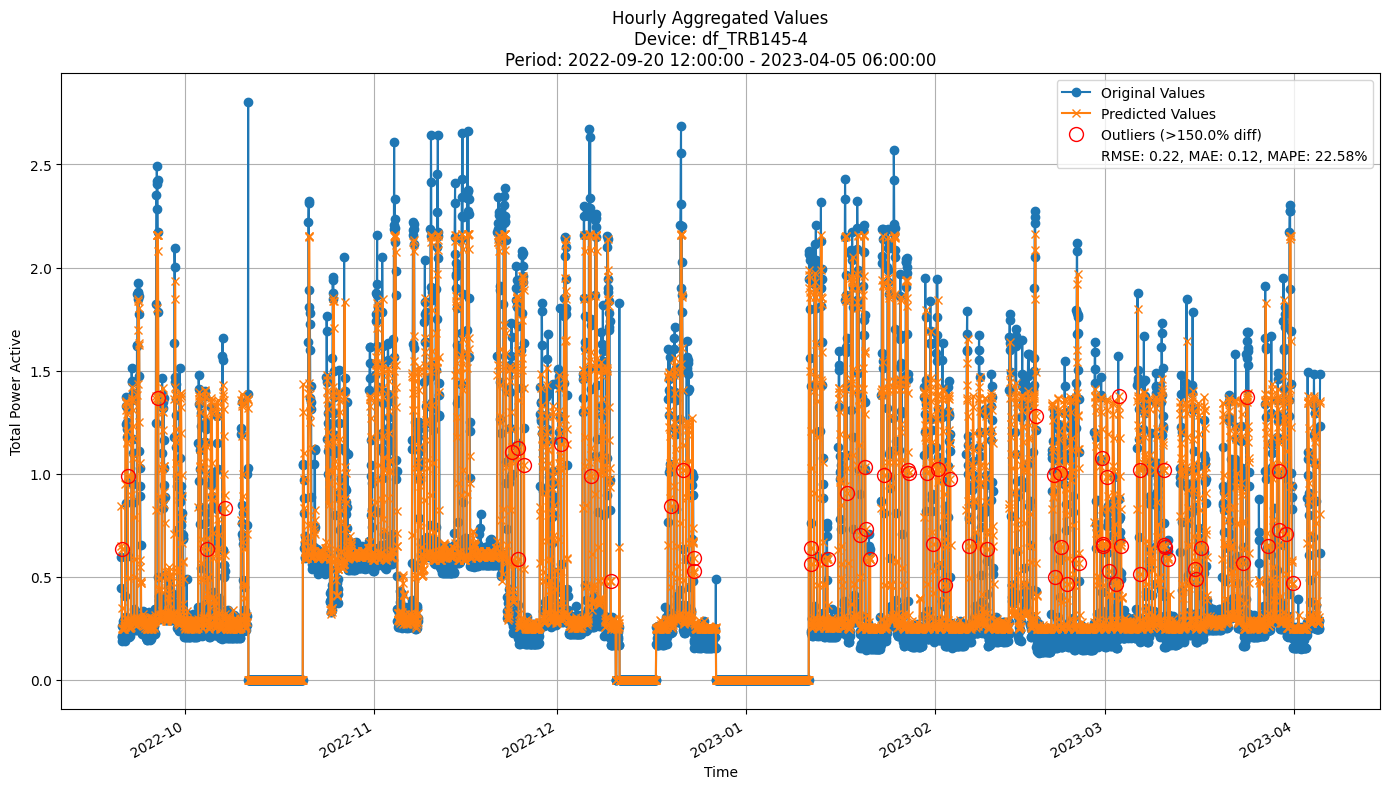

In [18]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

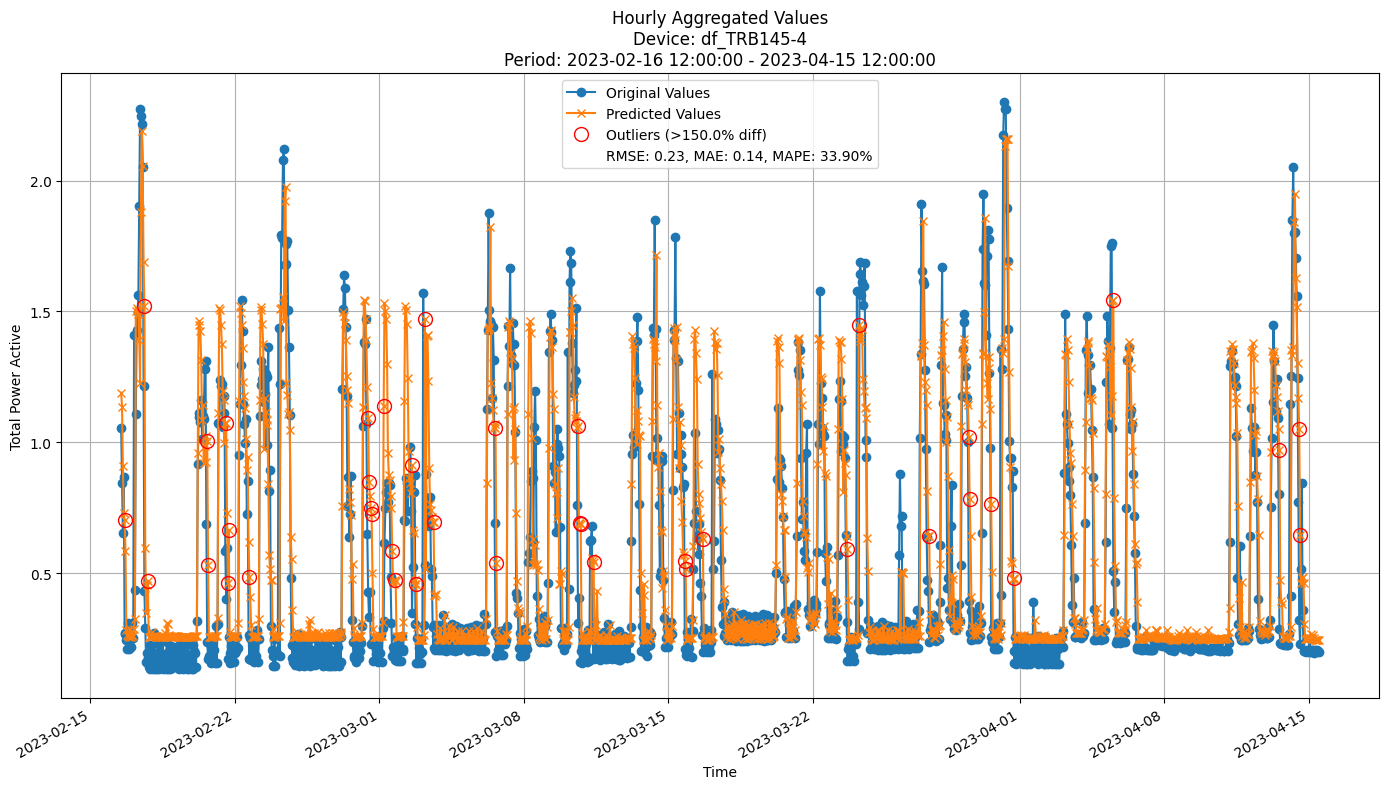

In [19]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [20]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

grace_period = 10
delta = 0.5
max_depth = 10
tau = 0.05

hoef = HoeffdingTreeRegressor(
        max_depth=max_depth,
        grace_period=grace_period,
        delta=delta,
        tau=tau,
        leaf_prediction="mean"
    )

hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_splits_seq_fit_predict(
    model=hoef, 
    train=train, 
    valid=valid, 
    incremental=True, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.3978
	MAE: 0.2563
	MAPE: 27.4439%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3978
	MAE: 0.2563
	MAPE: 27.4439%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 5.0512
	MAE: 3.8291
	MAPE: 19.4116%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 19.7146
	MAE: 16.4973
	MAPE: 18.1313%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 82.4866
	MAE: 82.4866
	MAPE: 16.8400%


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.4032
	MAE: 0.2650
	MAPE: 39.9377%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.4032
	MAE: 0.2650
	MAPE: 39.9377%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 4.3860
	MAE: 3.2684
	MAPE: 20.1893%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 8.5249
	MAE: 6.8162
	MAPE: 6.3368%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 27.2649
	MAE: 27.2649
	MAPE: 5.8908%


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.3195
	MAE: 0.2023
	MAPE: 42.2304%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3195
	MAE: 0.2023
	MAPE: 42.2304%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.2725
	MAE: 2.3390
	MAPE: 18.2403%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 8.9007
	MAE: 7.3824
	MAPE: 12.9930%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 36.9118
	MAE: 36.9118
	MAPE: 11.8600%


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2840
	MAE: 0.1644
	MAPE: 42.0583%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2840
	MAE: 0.1644
	MAPE: 42.0583%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.6981
	MAE: 1.9824
	MAPE: 24.2623%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 10.9288
	MAE: 10.9032
	MAPE: 20.5693%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 21.8064
	MAE: 21.8064
	MAPE: 19.6393%


#### Results

In [21]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.3150 ± 0.0867
	MAE: 0.2003 ± 0.0659
	MAPE: 0.3683 ± 0.1493
Hourly Metrics:
	RMSE: 0.2819 ± 0.0701
	MAE: 0.1604 ± 0.0444
	MAPE: 0.2936 ± 0.0992
Daily Metrics:
	RMSE: 3.0778 ± 1.4050
	MAE: 2.2249 ± 1.0467
	MAPE: 0.1758 ± 0.1001
Weekly Metrics:
	RMSE: 11.4314 ± 6.7043
	MAE: 8.5660 ± 4.9220
	MAPE: 0.1249 ± 0.0784
28_days Metrics:
	RMSE: 31.5977 ± 14.2935
	MAE: 26.4467 ± 11.6237
	MAPE: 0.1091 ± 0.0761


Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.3360 ± 0.0475
	MAE: 0.2119 ± 0.0361
	MAPE: 0.4073 ± 0.0697
Hourly Metrics:
	RMSE: 0.3219 ± 0.0521
	MAE: 0.1964 ± 0.0469
	MAPE: 0.3721 ± 0.0653
Daily Metrics:
	RMSE: 3.3036 ± 0.9732
	MAE: 2.4545 ± 0.7665
	MAPE: 0.2003 ± 0.0363
Weekly Metrics:
	RMSE: 10.6685 ± 4.7621
	MAE: 8.8619 ± 3.9

#### Training plots
Plot only the last period of predictions

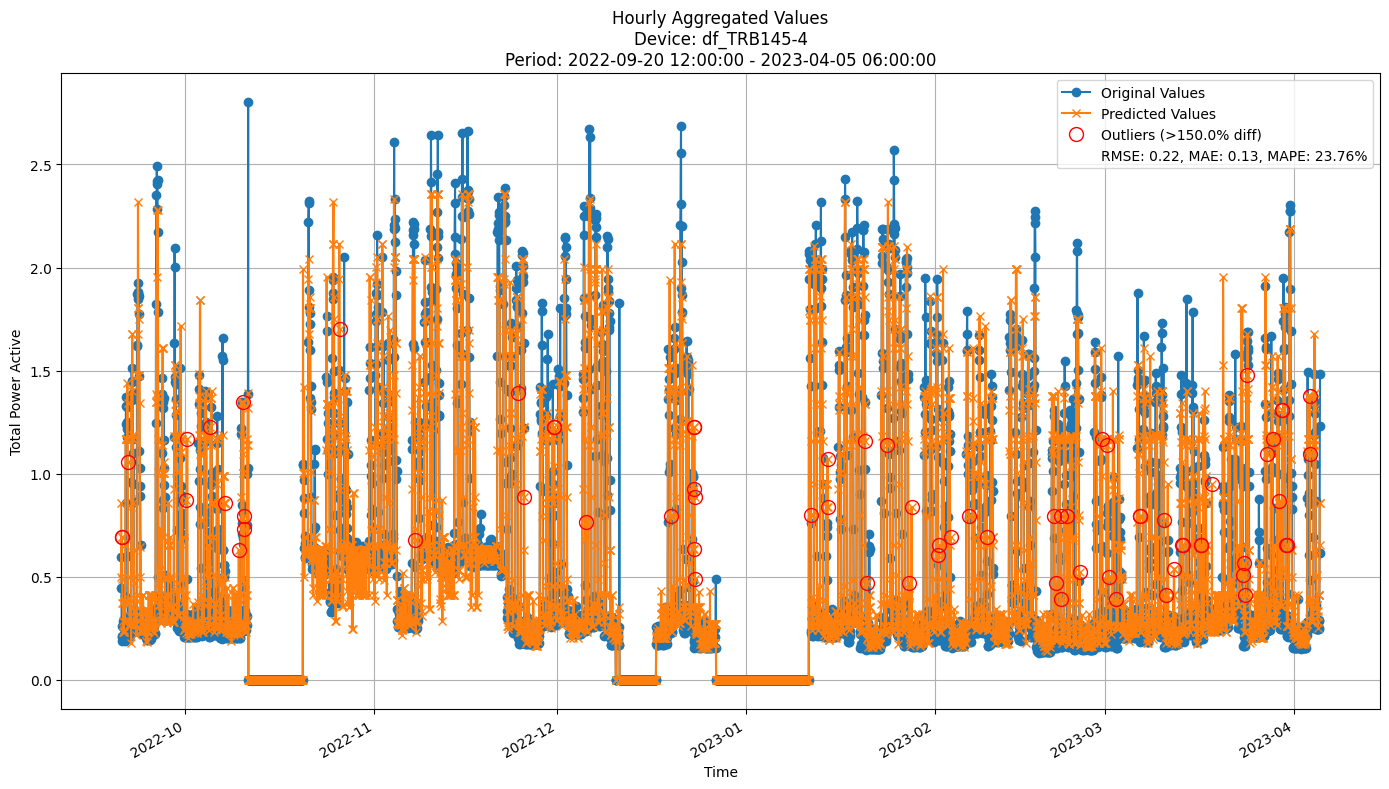

In [22]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

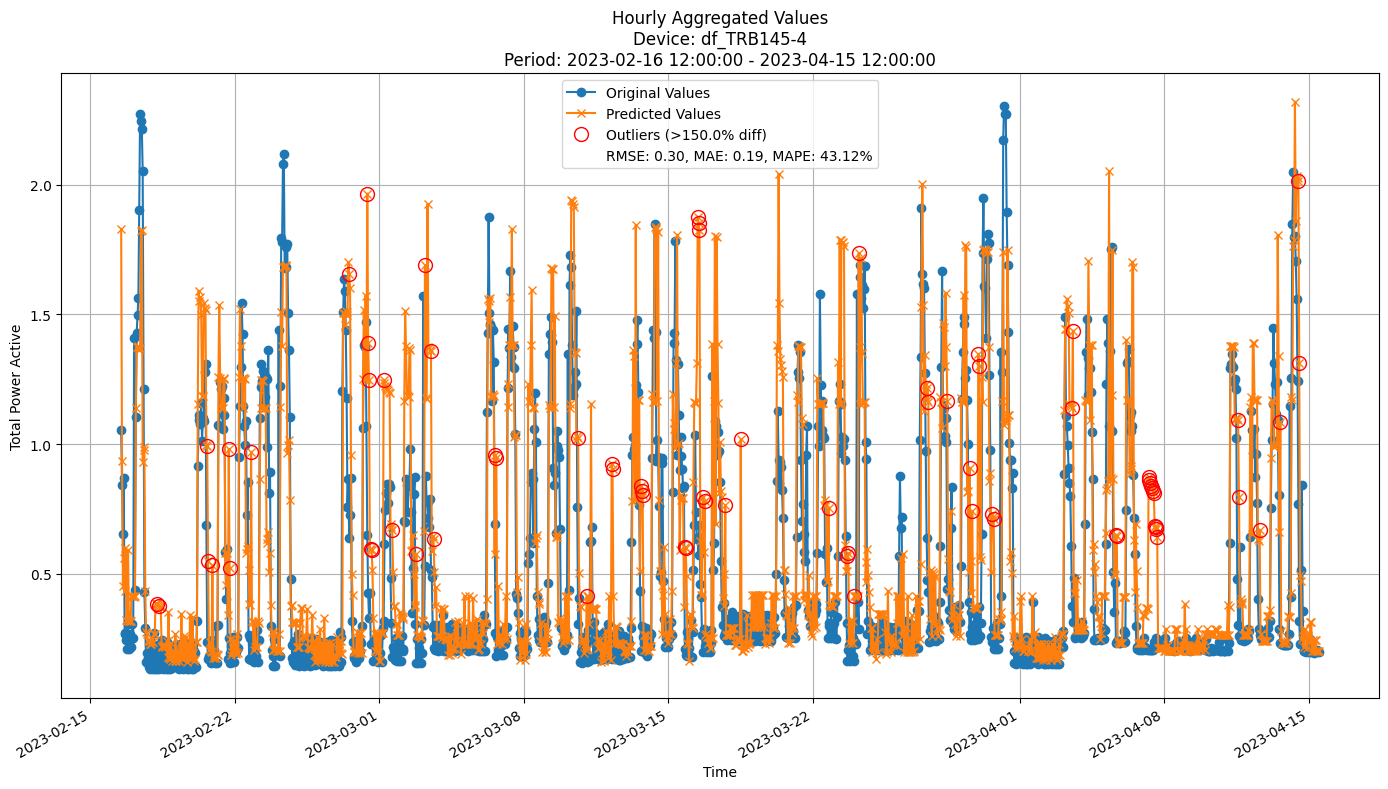

In [23]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [24]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

n_models = 10
max_features = 0.8
grace_period = 10
split_confidence = 0.5
depth = 10
tau = 0.01

arf_hf = ARFRegressor(
        n_models=n_models,
        max_features=max_features,
        aggregation_method='median',
        grace_period=grace_period,
        max_depth=depth,
        delta=split_confidence,
        tau=tau,
        seed=42,
    )

arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_splits_seq_fit_predict(
    model=arf_hf,
    train=train,
    valid=valid,
    incremental=True,
    update_freq=update_freq,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.3405
	MAE: 0.2352
	MAPE: 31.8058%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3405
	MAE: 0.2352
	MAPE: 31.8058%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 4.4627
	MAE: 3.5760
	MAPE: 21.2698%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 9.1615
	MAE: 7.3178
	MAPE: 7.9868%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 36.5889
	MAE: 36.5889
	MAPE: 7.4698%


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.3442
	MAE: 0.2426
	MAPE: 45.5051%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3442
	MAE: 0.2426
	MAPE: 45.5051%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.9387
	MAE: 3.1826
	MAPE: 24.6583%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 7.5235
	MAE: 6.8211
	MAPE: 6.0410%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 11.2301
	MAE: 11.2301
	MAPE: 2.4264%


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2483
	MAE: 0.1708
	MAPE: 39.8397%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2483
	MAE: 0.1708
	MAPE: 39.8397%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.6744
	MAE: 2.2453
	MAPE: 21.5807%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 11.2729
	MAE: 9.6010
	MAPE: 23.3047%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 48.0048
	MAE: 48.0048
	MAPE: 15.4243%


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2191
	MAE: 0.1486
	MAPE: 43.0197%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2191
	MAE: 0.1486
	MAPE: 43.0197%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.6913
	MAE: 2.3371
	MAPE: 30.6646%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 13.0285
	MAE: 12.8538
	MAPE: 23.6569%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 25.7076
	MAE: 25.7076
	MAPE: 23.1528%


#### Results

In [25]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.2768 ± 0.0723
	MAE: 0.1890 ± 0.0713
	MAPE: 0.4087 ± 0.2209
Hourly Metrics:
	RMSE: 0.2478 ± 0.0578
	MAE: 0.1510 ± 0.0475
	MAPE: 0.3238 ± 0.1496
Daily Metrics:
	RMSE: 3.0736 ± 1.2041
	MAE: 2.3295 ± 0.9760
	MAPE: 0.2110 ± 0.1224
Weekly Metrics:
	RMSE: 13.1930 ± 5.6795
	MAE: 10.4141 ± 5.2370
	MAPE: 0.1515 ± 0.0837
28_days Metrics:
	RMSE: 39.7904 ± 14.7552
	MAE: 31.8433 ± 11.1681
	MAPE: 0.1258 ± 0.0758

\Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.2814 ± 0.0431
	MAE: 0.1948 ± 0.0314
	MAPE: 0.4468 ± 0.0758
Hourly Metrics:
	RMSE: 0.2712 ± 0.0537
	MAE: 0.1819 ± 0.0457
	MAPE: 0.4100 ± 0.0814
Daily Metrics:
	RMSE: 3.1874 ± 0.8456
	MAE: 2.5560 ± 0.7313
	MAPE: 0.2452 ± 0.0555
Weekly Metrics:
	RMSE: 11.5179 ± 4.3480
	MAE: 9.8138 ± 3.

#### Training plots
Plot only the last period of predictions

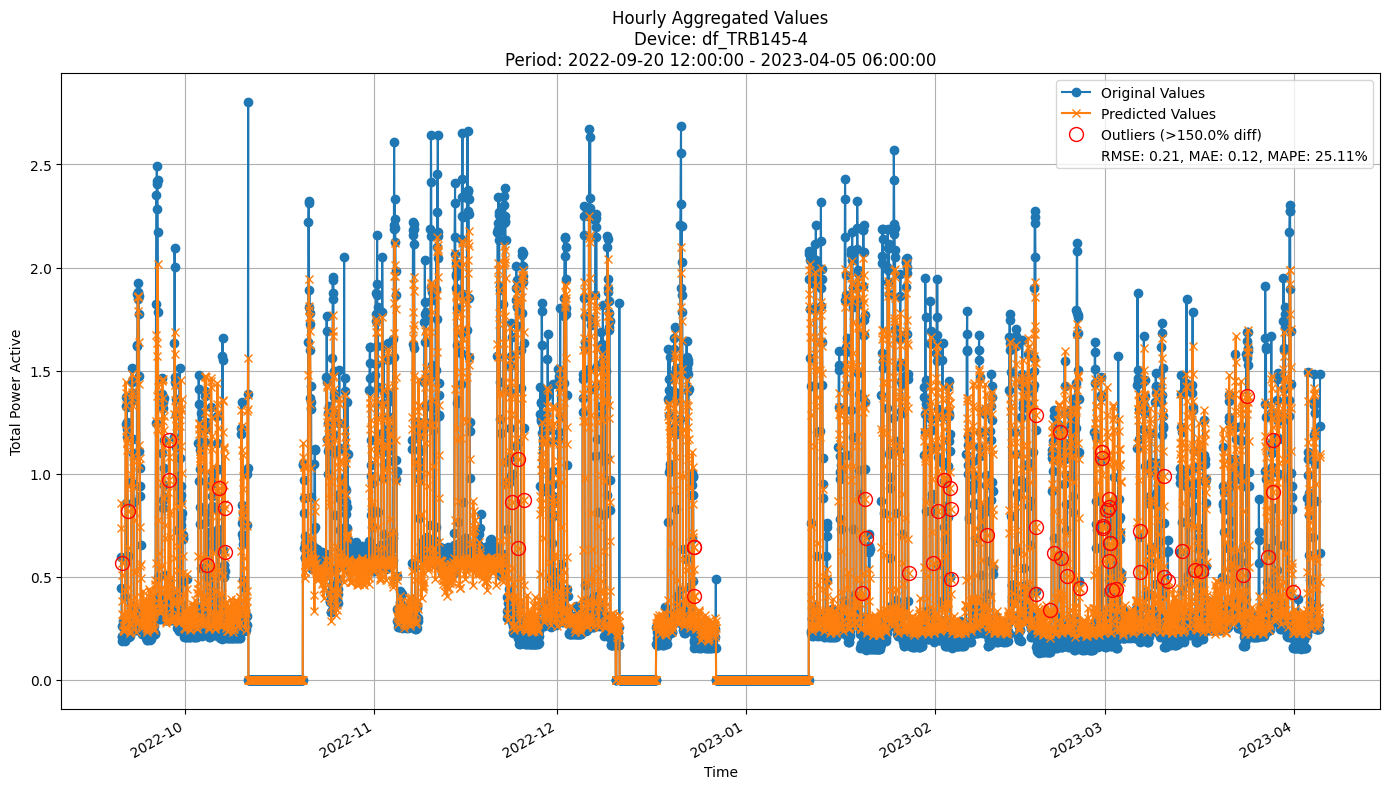

In [26]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

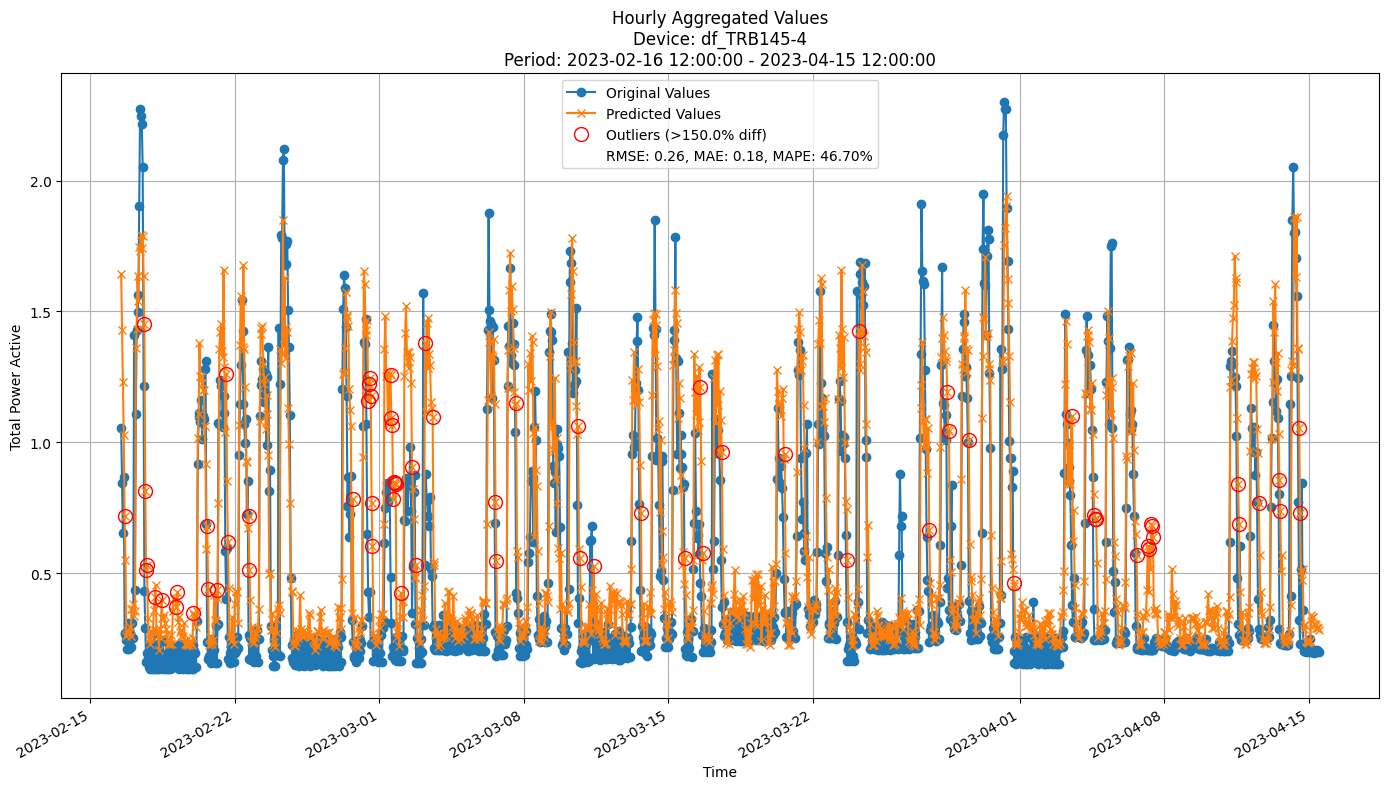

In [27]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [44]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario
grace_period = 10
split_confidence = 0.001
depth = 100
eagerness = 100
fodt = fastodt.FastODT(
        depth=depth,
        grace_period=grace_period,
        split_confidence=split_confidence,
        option='hf',
        eagerness = eagerness
    )

fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_splits_seq_fit_predict(
    model=fodt, 
    train=train, 
    valid=valid, 
    incremental=True, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.5681
	MAE: 0.3992
	MAPE: 41.4334%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.5681
	MAE: 0.3992
	MAPE: 41.4334%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 9.9891
	MAE: 8.1913
	MAPE: 38.6274%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 43.4788
	MAE: 37.2779
	MAPE: 36.7221%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 186.3893
	MAE: 186.3893
	MAPE: 38.0521%


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.6017
	MAE: 0.4177
	MAPE: 56.4412%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.6017
	MAE: 0.4177
	MAPE: 56.4412%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 9.0887
	MAE: 7.5360
	MAPE: 45.5282%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 36.2233
	MAE: 34.6935
	MAPE: 30.0873%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 138.7742
	MAE: 138.7742
	MAPE: 29.9832%


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.3137
	MAE: 0.2338
	MAPE: 60.1693%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3137
	MAE: 0.2338
	MAPE: 60.1693%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.8282
	MAE: 3.1193
	MAPE: 36.7059%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 6.7102
	MAE: 5.3999
	MAPE: 24.5752%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 17.0572
	MAE: 17.0572
	MAPE: 5.4806%


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.3280
	MAE: 0.2670
	MAPE: 92.4171%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3280
	MAE: 0.2670
	MAPE: 92.4171%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 5.0343
	MAE: 4.0119
	MAPE: 74.7939%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 15.6608
	MAE: 15.0253
	MAPE: 30.9361%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 30.0507
	MAE: 30.0507
	MAPE: 27.0642%


#### Results

In [45]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.4525 ± 0.0277
	MAE: 0.3147 ± 0.0198
	MAPE: 0.5579 ± 0.0506
Hourly Metrics:
	RMSE: 0.4073 ± 0.0301
	MAE: 0.2553 ± 0.0257
	MAPE: 0.4510 ± 0.0407
Daily Metrics:
	RMSE: 6.3440 ± 0.7014
	MAE: 4.6328 ± 0.6141
	MAPE: 0.3503 ± 0.0149
Weekly Metrics:
	RMSE: 25.2630 ± 6.3498
	MAE: 19.4316 ± 5.0302
	MAPE: 0.2454 ± 0.0446
28_days Metrics:
	RMSE: 85.4652 ± 31.5895
	MAE: 62.3957 ± 24.4067
	MAPE: 0.1883 ± 0.0458

\Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.4492 ± 0.1132
	MAE: 0.3299 ± 0.0695
	MAPE: 0.7187 ± 0.1826
Hourly Metrics:
	RMSE: 0.4277 ± 0.1062
	MAE: 0.3028 ± 0.0736
	MAPE: 0.6566 ± 0.1774
Daily Metrics:
	RMSE: 6.1703 ± 2.2037
	MAE: 4.9737 ± 1.8681
	MAPE: 0.4790 ± 0.1218
Weekly Metrics:
	RMSE: 20.5208 ± 12.6630
	MAE: 17.7447 ± 

#### Training plots
Plot only the last period of predictions

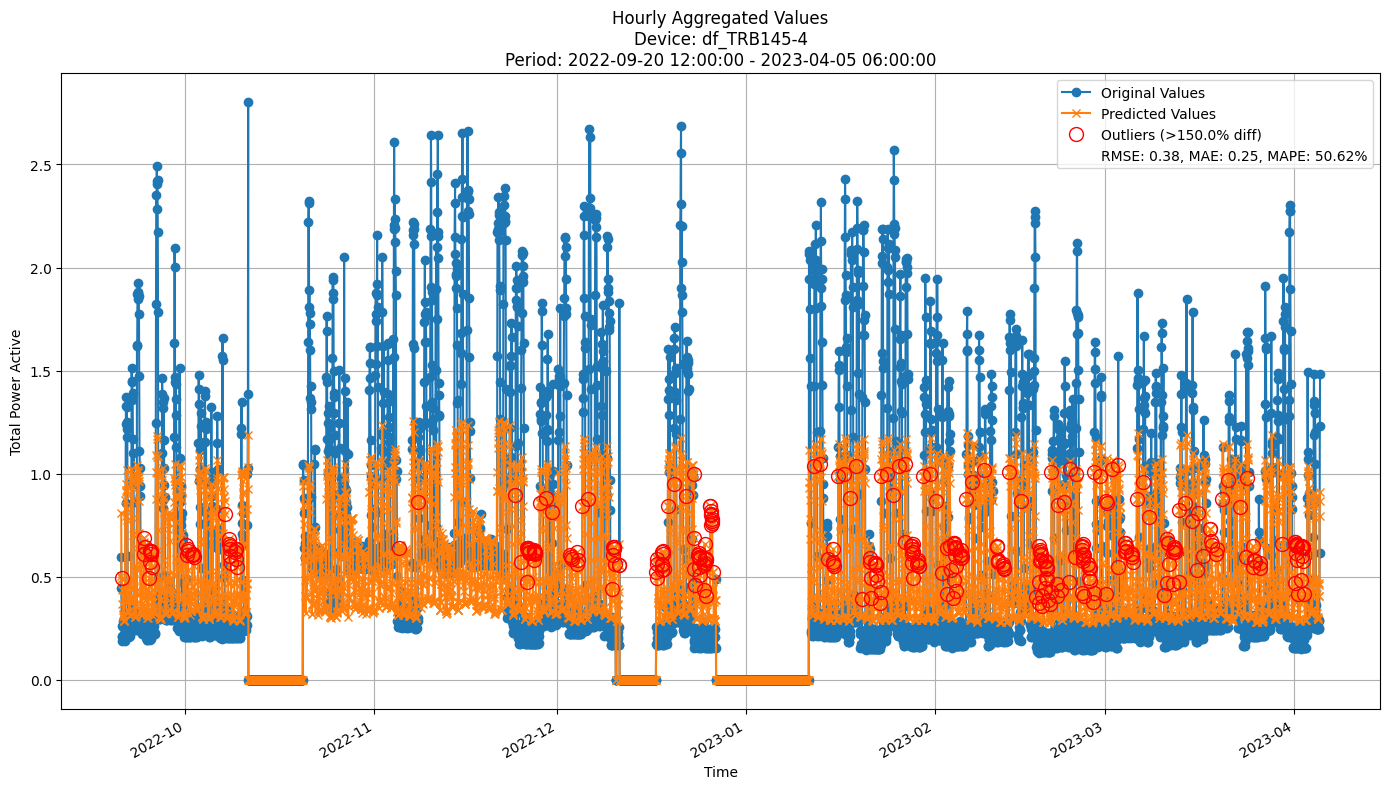

In [46]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

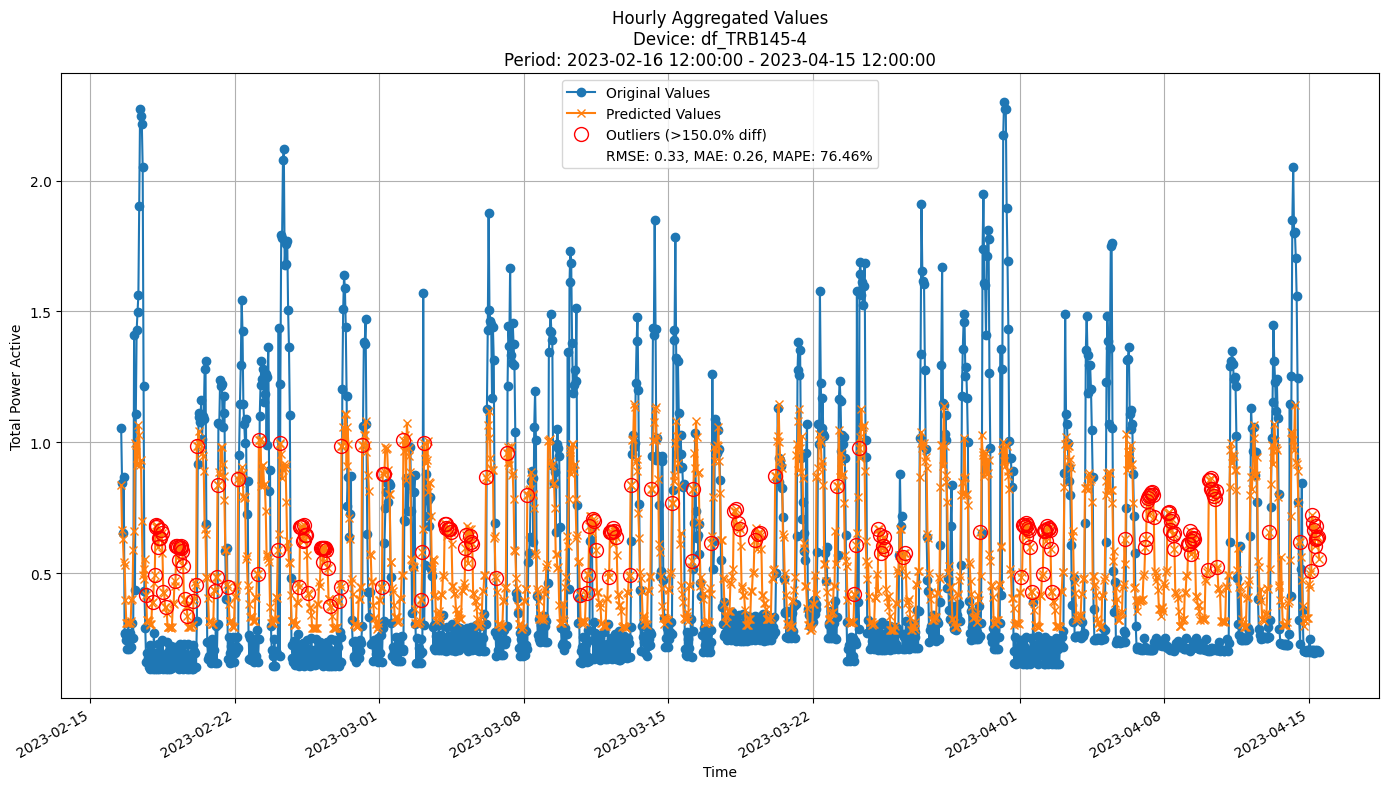

In [47]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [32]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

n_models = 20
grace_period = 0
aggregation_method = "mean"
split_confidence = 0.005
tau = 0.01
max_depth = 100
eagerness = 200

arf = ARFRegressorFODT(
        n_models=n_models,
        aggregation_method=aggregation_method,
        grace_period=grace_period,
        max_depth=max_depth,
        delta=split_confidence,
        tau=tau,
        seed=42,
        max_feature=0.7,
        eagerness=eagerness,
    )

arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_splits_seq_fit_predict(
    model=arf,
    train=train,
    valid=valid,
    incremental=True,
    update_freq=update_freq,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.4700
	MAE: 0.3139
	MAPE: 36.8185%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.4700
	MAE: 0.3139
	MAPE: 36.8185%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 7.3526
	MAE: 6.1560
	MAPE: 34.1577%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 22.7751
	MAE: 20.8701
	MAPE: 26.1551%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 104.3505
	MAE: 104.3505
	MAPE: 21.3036%


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.4910
	MAE: 0.3943
	MAPE: 83.1303%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.4910
	MAE: 0.3943
	MAPE: 83.1303%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 6.5557
	MAE: 5.2800
	MAPE: 47.4860%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 10.5917
	MAE: 9.6706
	MAPE: 8.6620%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 2.6391
	MAE: 2.6391
	MAPE: 0.5702%


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.3175
	MAE: 0.2470
	MAPE: 68.8606%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3175
	MAE: 0.2470
	MAPE: 68.8606%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 4.0183
	MAE: 3.0310
	MAPE: 40.6027%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 10.2407
	MAE: 7.3129
	MAPE: 40.9900%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 35.6857
	MAE: 35.6857
	MAPE: 11.4661%


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.3085
	MAE: 0.2758
	MAPE: 98.5061%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3085
	MAE: 0.2758
	MAPE: 98.5061%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 4.7879
	MAE: 4.1180
	MAPE: 70.8641%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 20.5032
	MAE: 20.2176
	MAPE: 40.4224%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 40.4351
	MAE: 40.4351
	MAPE: 36.4166%


#### Results

In [33]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.4286 ± 0.0246
	MAE: 0.3299 ± 0.0446
	MAPE: 0.7577 ± 0.1726
Hourly Metrics:
	RMSE: 0.3861 ± 0.0308
	MAE: 0.2686 ± 0.0462
	MAPE: 0.6176 ± 0.1505
Daily Metrics:
	RMSE: 5.9657 ± 0.6370
	MAE: 4.4236 ± 0.7340
	MAPE: 0.4291 ± 0.0970
Weekly Metrics:
	RMSE: 23.0800 ± 4.6751
	MAE: 17.5447 ± 3.1812
	MAPE: 0.2756 ± 0.0720
28_days Metrics:
	RMSE: 71.3200 ± 22.2649
	MAE: 54.9935 ± 15.3465
	MAPE: 0.2190 ± 0.0529

\Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.4066 ± 0.0735
	MAE: 0.3371 ± 0.0665
	MAPE: 0.9740 ± 0.3693
Hourly Metrics:
	RMSE: 0.3878 ± 0.0688
	MAE: 0.3071 ± 0.0581
	MAPE: 0.8687 ± 0.2820
Daily Metrics:
	RMSE: 5.8333 ± 1.2455
	MAE: 4.6279 ± 1.2051
	MAPE: 0.5619 ± 0.1561
Weekly Metrics:
	RMSE: 21.0222 ± 10.0909
	MAE: 18.2179 ± 

#### Training plots
Plot only the last period of predictions

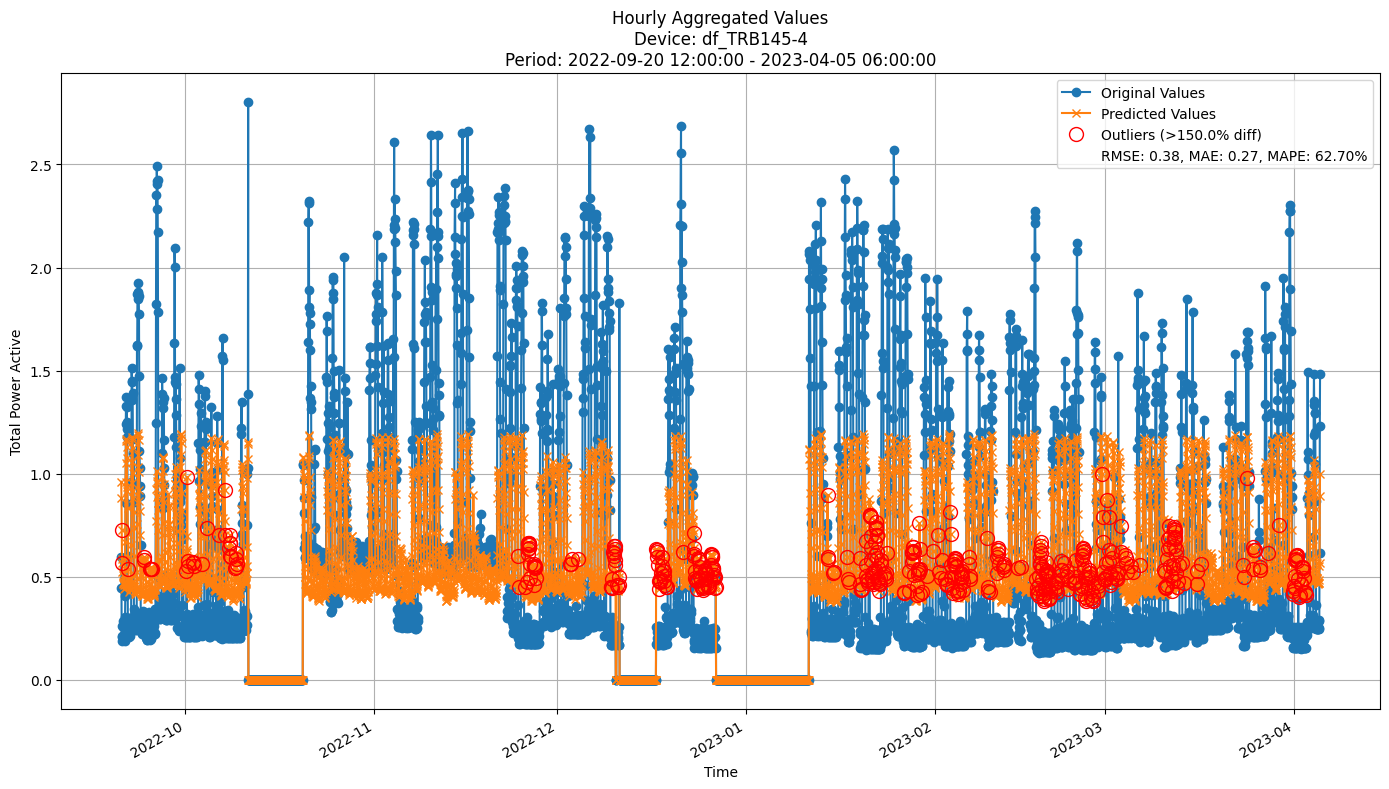

In [34]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

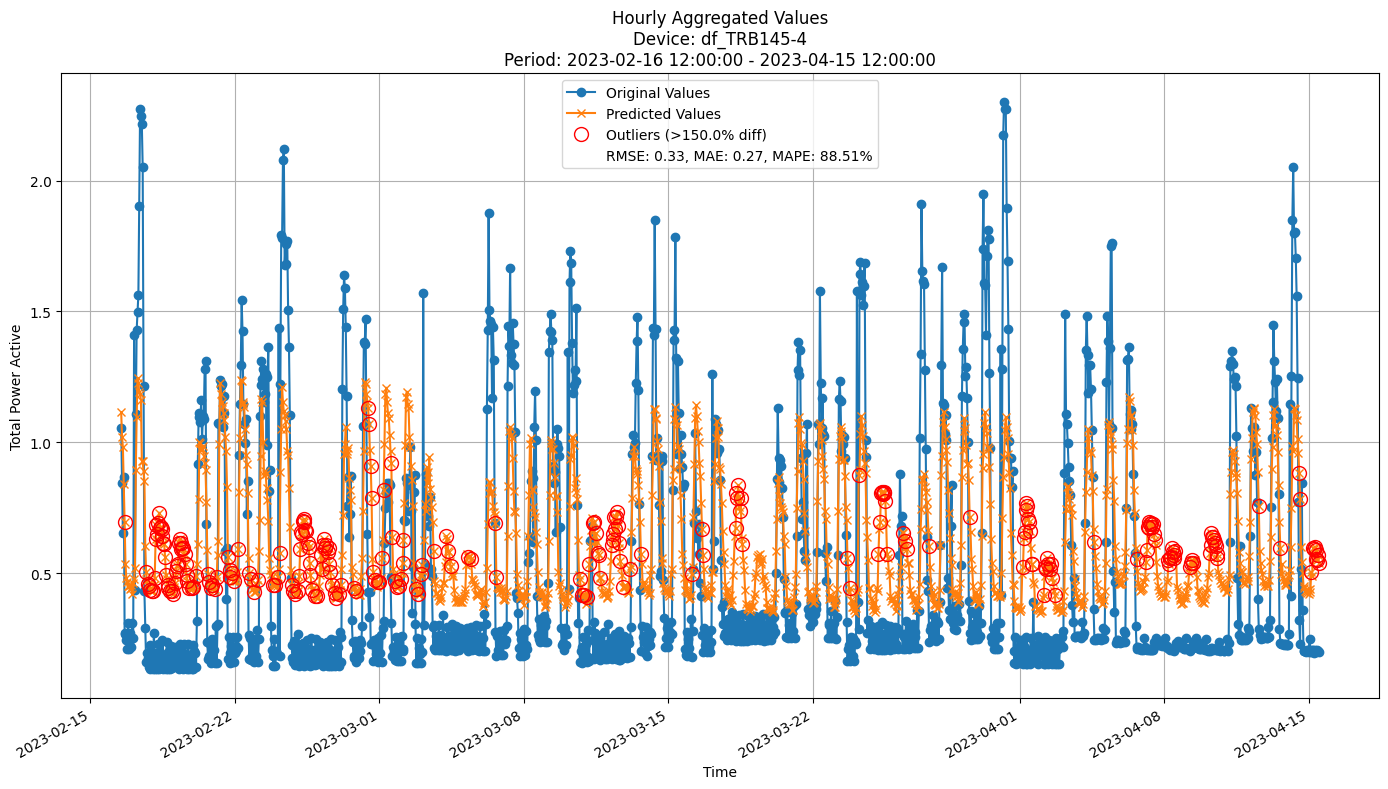

In [35]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [36]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:
split_confidence_hf = 0.001
n_trees = 10
depth = 100
grace_period = 10
max_feature = 1.0
eagerness = 1000
incb = IncubationBoost(
    fastodt.FastODT,
    length=n_trees,
    incubationMode = "SHIFT_LEFT",
    baseLearnerOptions = (depth, grace_period, split_confidence, "hf", max_features, eagerness),
    verbose=False
    )

incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_splits_seq_fit_predict(
    model=incb, 
    train=train, 
    valid=valid, 
    incremental=True, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.5600
	MAE: 0.4062
	MAPE: 42.2152%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.5600
	MAE: 0.4062
	MAPE: 42.2152%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 10.4466
	MAE: 9.1050
	MAPE: 43.7544%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 48.9482
	MAE: 42.9348
	MAPE: 44.2094%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 214.6741
	MAE: 214.6741
	MAPE: 43.8266%


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.5829
	MAE: 0.3922
	MAPE: 47.1748%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.5829
	MAE: 0.3922
	MAPE: 47.1748%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 9.3657
	MAE: 7.9774
	MAPE: 44.8446%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 42.1030
	MAE: 41.5858
	MAPE: 36.4140%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 166.3432
	MAE: 166.3432
	MAPE: 35.9397%


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2841
	MAE: 0.2053
	MAPE: 52.1767%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2841
	MAE: 0.2053
	MAPE: 52.1767%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.2948
	MAE: 2.7189
	MAPE: 32.0938%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 7.5075
	MAE: 5.7774
	MAPE: 28.4876%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 23.5046
	MAE: 23.5046
	MAPE: 7.5522%


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2672
	MAE: 0.2037
	MAPE: 67.1362%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2672
	MAE: 0.2037
	MAPE: 67.1362%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.3207
	MAE: 2.7901
	MAPE: 50.2169%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 11.9019
	MAE: 11.6770
	MAPE: 23.5050%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 23.3539
	MAE: 23.3539
	MAPE: 21.0330%


#### Results

In [37]:
print("\n\nTrain period metrics:")
all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, verbose=True)
print("\n\nValid period metrics:")
all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.4158 ± 0.0316
	MAE: 0.2822 ± 0.0200
	MAPE: 0.4525 ± 0.0271
Hourly Metrics:
	RMSE: 0.3740 ± 0.0296
	MAE: 0.2289 ± 0.0244
	MAPE: 0.3663 ± 0.0285
Daily Metrics:
	RMSE: 6.0131 ± 0.7595
	MAE: 4.4374 ± 0.6991
	MAPE: 0.3034 ± 0.0140
Weekly Metrics:
	RMSE: 26.8426 ± 5.8830
	MAE: 21.1470 ± 5.2318
	MAPE: 0.2313 ± 0.0286
28_days Metrics:
	RMSE: 92.6880 ± 29.8185
	MAE: 69.0013 ± 23.7753
	MAPE: 0.2141 ± 0.0733


Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.4134 ± 0.1211
	MAE: 0.2944 ± 0.0771
	MAPE: 0.5845 ± 0.1120
Hourly Metrics:
	RMSE: 0.3941 ± 0.1175
	MAE: 0.2722 ± 0.0857
	MAPE: 0.5422 ± 0.1402
Daily Metrics:
	RMSE: 5.7236 ± 2.7161
	MAE: 4.7516 ± 2.4423
	MAPE: 0.4103 ± 0.0828
Weekly Metrics:
	RMSE: 21.7975 ± 15.2845
	MAE: 19.2083 ± 

#### Train plots
Plot only the last period of predictions


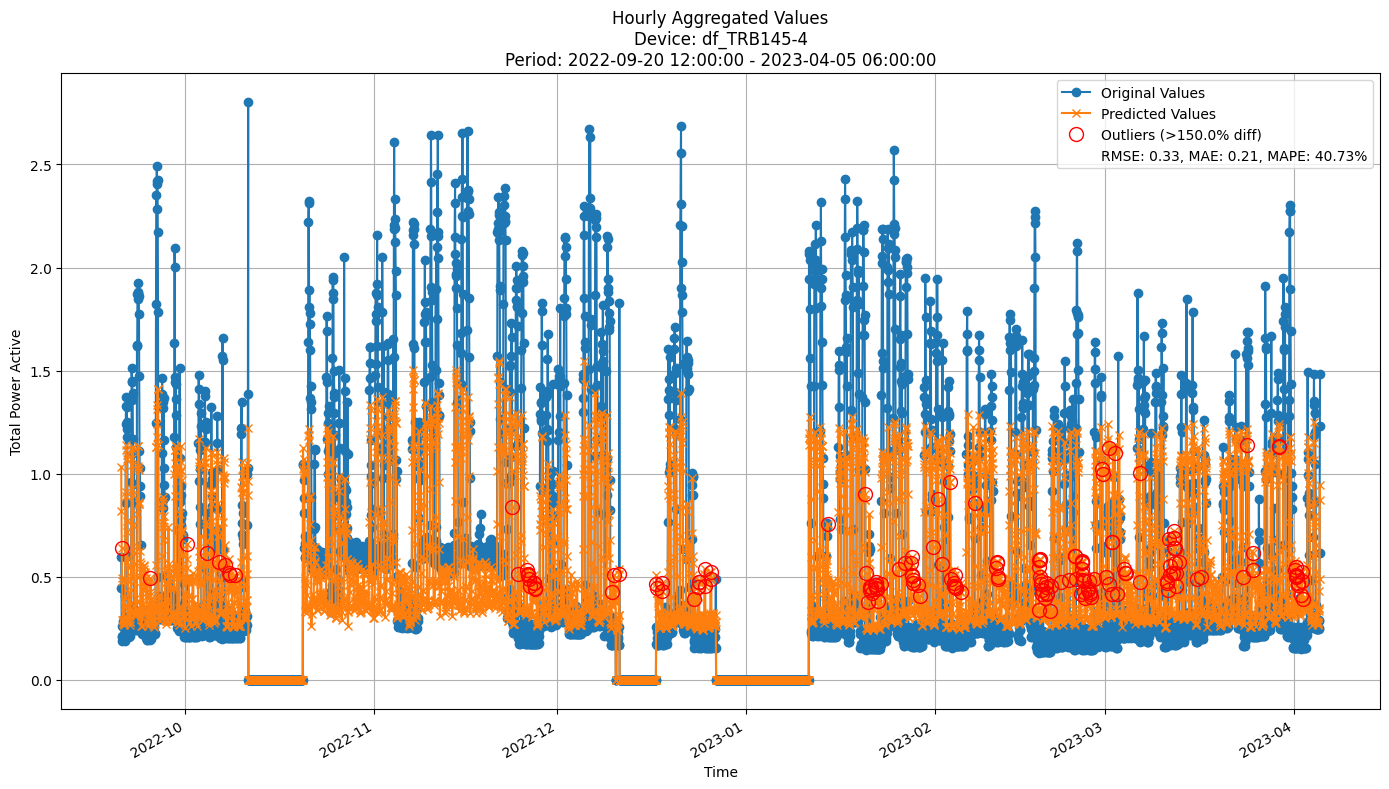

In [38]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

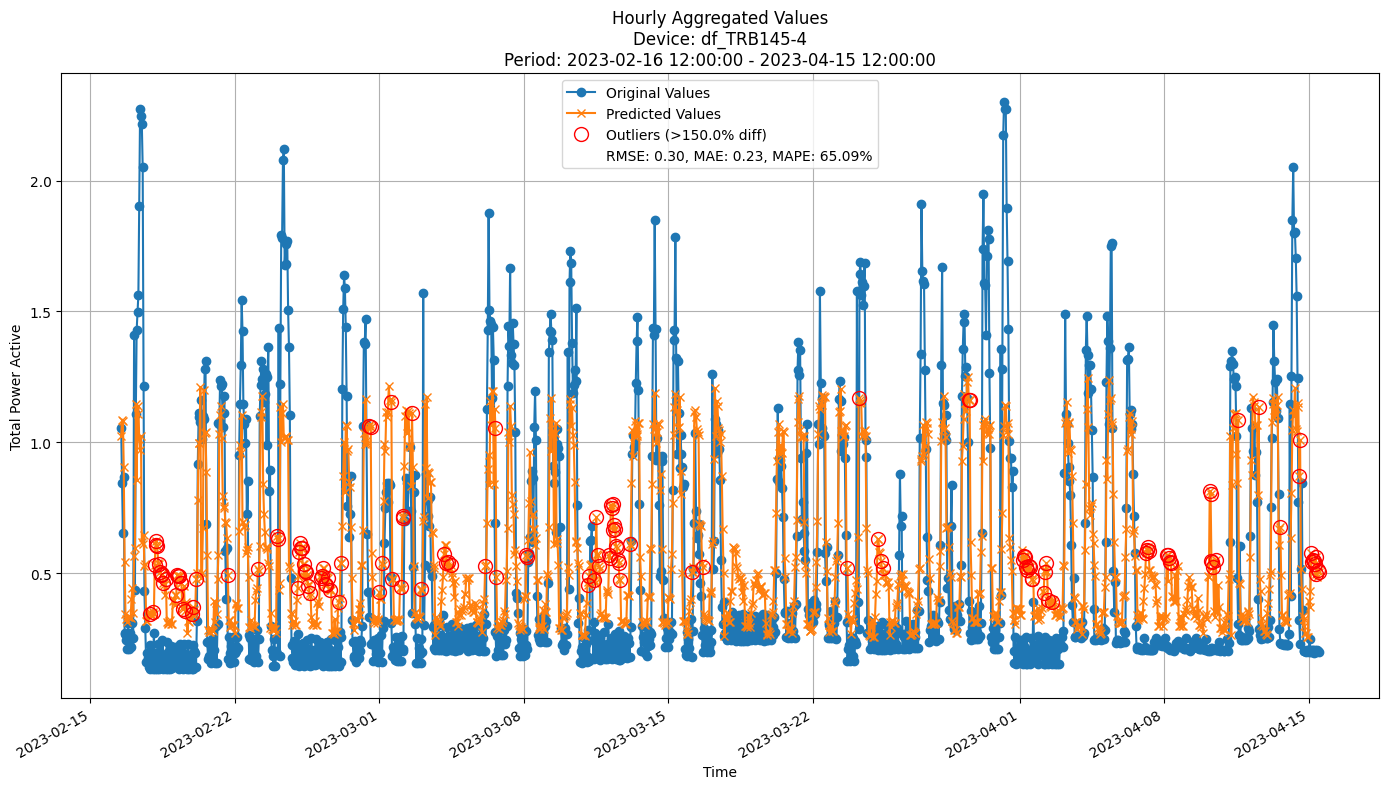

In [39]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            device_id=device_id,
                            outlier_threshold=1.5)

## Model Comparison

### Overall validation results

In [48]:
model_metrics = {
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": all_time_valid_metrics,
}

agg_level = "hourly"
metrics = ["rmse", "mae", "mape"]

device_ids = set()
for m in model_metrics.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

def format_metric(val, is_mape=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_mape:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_mape:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

for device_id in device_ids:
    rows = []
    for model, mdict in model_metrics.items():
        if device_id in mdict and agg_level in mdict[device_id]:
            vals = mdict[device_id][agg_level]
            row = [model]
            for m in metrics:
                is_mape = (m == "mape")
                row.append(format_metric(vals.get(m, None), is_mape=is_mape))
            rows.append(row)
    df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)"])
    print(f"\nDevice: {device_id} | Aggregation: {agg_level}")
    display(df)


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%)
0,GBDT,0.239 ± 0.047,0.160 ± 0.037,36.078 ± 6.691
1,RandomForest,0.208 ± 0.018,0.109 ± 0.012,19.300 ± 2.245
2,HoeffdingTree,0.322 ± 0.052,0.196 ± 0.047,37.210 ± 6.531
3,ARF_Hoeffding,0.271 ± 0.054,0.182 ± 0.046,41.000 ± 8.141
4,FastODT,0.428 ± 0.106,0.303 ± 0.074,65.659 ± 17.745
5,ARF_FastODT,0.388 ± 0.069,0.307 ± 0.058,86.870 ± 28.198
6,IncubationBoost,0.394 ± 0.117,0.272 ± 0.086,54.216 ± 14.019


### By-period validation results

In [41]:
model_period_metrics = {
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, model_period_metrics, agg_level, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    metric_name: "mape" or "rmse"
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in model_period_metrics.items():
            if device_id in mdict:
                if metric_name == "mape":
                    vals = [period[agg_level]["mape"]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[agg_level][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = "MAPE (%)" if metric_name == "mape" else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {agg_level} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label} (lower is better):")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### MAPE

In [42]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    model_period_metrics=model_period_metrics,
    agg_level=agg_level,
    metric_name="mape",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | MAPE (%) per period


,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,25.995,22.810,27.444,31.806,43.290,36.818,42.215,32.911143
Period 2,37.247,28.018,39.938,45.505,59.245,83.130,47.175,48.608286
Period 3,30.910,24.287,27.497,28.762,50.591,82.297,33.116,39.637143
Period 4,40.855,35.336,36.845,42.922,80.166,134.579,60.547,61.607143
Period 5,48.312,42.981,44.459,55.149,93.800,103.901,77.145,66.535286
Period 6,32.756,28.652,42.230,39.840,64.853,68.861,52.177,47.052714
Period 7,36.475,24.973,42.058,43.020,90.891,98.506,67.136,57.579857



Absolute gain/drop in MAPE (%) (lower is better):


,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,11.252,5.208,12.494,13.699,15.955,46.312,4.960,15.697
Period 3 - Period 2,-6.337,-3.731,-12.441,-16.743,-8.654,-0.833,-14.059,-8.971
Period 4 - Period 3,9.945,11.049,9.348,14.160,29.575,52.282,27.431,21.970
Period 5 - Period 4,7.457,7.645,7.614,12.227,13.634,-30.678,16.598,4.928
Period 6 - Period 5,-15.556,-14.329,-2.229,-15.309,-28.947,-35.040,-24.968,-19.483
Period 7 - Period 6,3.719,-3.679,-0.172,3.180,26.038,29.645,14.959,10.527


#### RMSE

In [43]:
# RMSE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    model_period_metrics=model_period_metrics,
    agg_level=agg_level,
    metric_name="rmse",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | RMSE per period


,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.311,0.294,0.398,0.341,0.596,0.470,0.560,0.424286
Period 2,0.310,0.296,0.403,0.344,0.675,0.491,0.583,0.443143
Period 3,0.203,0.197,0.263,0.190,0.447,0.349,0.359,0.286857
Period 4,0.221,0.241,0.288,0.269,0.505,0.428,0.370,0.331714
Period 5,0.234,0.254,0.297,0.287,0.419,0.351,0.336,0.311143
Period 6,0.215,0.224,0.320,0.248,0.382,0.317,0.284,0.284286
Period 7,0.183,0.183,0.284,0.219,0.371,0.308,0.267,0.259286



Absolute gain/drop in RMSE (lower is better):


,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.001,0.002,0.005,0.003,0.079,0.021,0.023,0.019
Period 3 - Period 2,-0.107,-0.099,-0.140,-0.154,-0.228,-0.142,-0.224,-0.156
Period 4 - Period 3,0.018,0.044,0.025,0.079,0.058,0.079,0.011,0.045
Period 5 - Period 4,0.013,0.013,0.009,0.018,-0.086,-0.077,-0.034,-0.021
Period 6 - Period 5,-0.019,-0.030,0.023,-0.039,-0.037,-0.034,-0.052,-0.027
Period 7 - Period 6,-0.032,-0.041,-0.036,-0.029,-0.011,-0.009,-0.017,-0.025
